# Lecture 8 — Class Exercise
## Choropleth Maps

> **Push to:** `week08/lecture08_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook_connected+png'

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json

## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


World average: 67.0 years across 142 countries
           mean_gap  countries  below_avg
continent                                
Africa        -12.2         52         45
Asia            3.7         33         10
Americas        6.6         25          2
Europe         10.6         30          0
Oceania        13.7          2          0


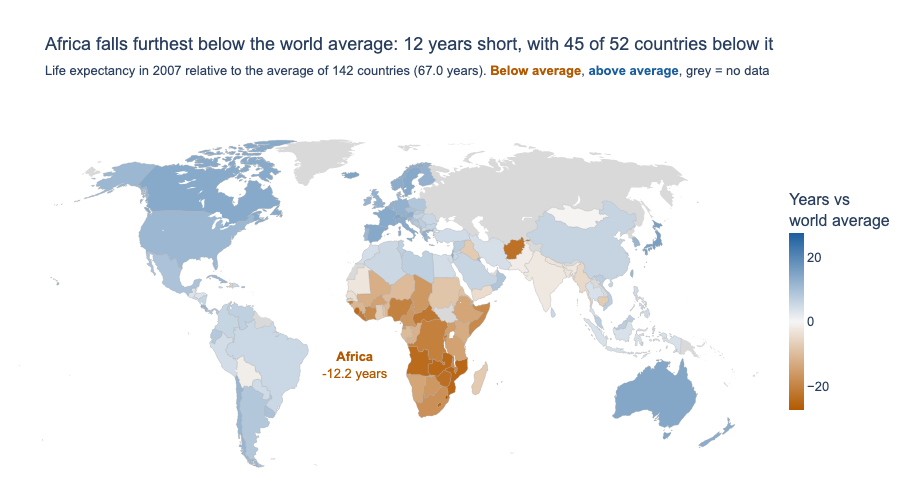

In [2]:
# Task 1 — life expectancy relative to the world average, 2007
gm = px.data.gapminder()
gm_2007 = gm.loc[gm['year'] == 2007].copy()

world_avg = gm_2007['lifeExp'].mean()
gm_2007['deviation'] = gm_2007['lifeExp'] - world_avg

# compare continents first, so the title states what the data shows
by_continent = (
    gm_2007.groupby('continent')['deviation']
    .agg(mean_gap='mean', countries='size', below_avg=lambda s: (s < 0).sum())
    .sort_values('mean_gap')
)
print(f"World average: {world_avg:.1f} years across {len(gm_2007)} countries")
print(by_continent.round(1))

lowest = by_continent.index[0]
gap = by_continent.loc[lowest, 'mean_gap']
n_below = by_continent.loc[lowest, 'below_avg']
n_total = by_continent.loc[lowest, 'countries']

# orange = below average, blue = above (safe for colour vision deficiency), neutral at zero
BELOW, ABOVE = '#B35900', '#1B5E9E'

fig = px.choropleth(
    data_frame=gm_2007,
    locations='iso_alpha',
    locationmode='ISO-3',
    color='deviation',
    color_continuous_scale=[BELOW, '#F5F5F5', ABOVE],
    color_continuous_midpoint=0,
    hover_name='country',
    hover_data={'lifeExp': ':.1f', 'deviation': ':+.1f', 'iso_alpha': False},
    labels={'lifeExp': 'Life expectancy (years)', 'deviation': 'vs world average (years)'},
    projection='natural earth',
    template='plotly_white',
    height=500, width=900
)

fig.update_traces(marker_line_color='#AAAAAA', marker_line_width=0.3)

# label the continent in the ocean beside it, so the text stays readable
fig.add_scattergeo(
    lon=[-13], lat=[-14],
    text=[f"<b>{lowest}</b><br>{gap:+.1f} years"],
    mode='text',
    textfont=dict(color=BELOW, size=13),
    hoverinfo='skip',
    showlegend=False
)

fig.update_layout(
    title=dict(
        text=f"{lowest} falls furthest below the world average: "
             f"{abs(gap):.0f} years short, with {n_below} of {n_total} countries below it",
        subtitle=dict(text=(
            f"Life expectancy in 2007 relative to the average of {len(gm_2007)} countries ({world_avg:.1f} years). "
            f"<span style='color:{BELOW}'><b>Below average</b></span>, "
            f"<span style='color:{ABOVE}'><b>above average</b></span>, grey = no data"
        ))
    ),
    font=dict(family='Arial', size=13),
    geo=dict(
        showframe=False,
        showcoastlines=False,
        showland=True,
        landcolor='#D9D9D9',
        lataxis_range=[-58, 84]      # crop Antarctica, which has no data
    ),
    coloraxis_colorbar=dict(title='Years vs<br>world average', thickness=15, len=0.6),
    margin=dict(l=0, r=0, t=100, b=0)
)

fig.show()

### Task 1 — Design decisions

**Chart type chosen** (`px.choropleth`) **and reason:**

Plotly's built-in country shapes match Gapminder's ISO-3 codes, so no GeoJSON is needed. The story is a world-scale pattern, so a street-level tile basemap from `px.choropleth_map` would only add clutter.

**Colour scale chosen** (diverging) **and reason:**

The data has a meaningful midpoint: zero means a country sits exactly on the world average. A diverging scale shows both direction and distance from it. I used orange and blue instead of red and green so that the map stays readable with colour vision deficiency.

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** Eurostat GISCO, NUTS 2024 level 2 regions at 1:20 million ([download](https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2024_4326_LEVL_2.geojson)).

**Dataset:** Eurostat `lfst_r_lfu3rt`, unemployment rate for ages 15–74, both sexes, all education levels ([download](https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/lfst_r_lfu3rt/A.TOTAL.T.Y15-74.PC.?format=SDMX-CSV&compressed=false&startPeriod=2024)). Its `geo` column holds the same codes as `NUTS_ID` in the GeoJSON, so `featureidkey='properties.NUTS_ID'`.

**Chart type chosen** (`px.choropleth`) **and reason:**

The finding is a continent-wide pattern, so streets and place names from a tile basemap (`px.choropleth_map`) would only compete with it. `px.choropleth` also supports `fitbounds='locations'` and an equal-area projection, and it needs no map tiles to export as a static image for GitHub.

**Colour scale chosen** (sequential) **and reason:**

An unemployment rate runs in one direction, from low to high, and the question is where it is highest rather than which side of a benchmark a region falls on. A single-hue blue scale shows that without a false midpoint, and it leaves orange free to mark the ten highest regions.

{'NUTS_ID': 'ITC4', 'LEVL_CODE': 2, 'CNTR_CODE': 'IT', 'NAME_LATN': 'Lombardia', 'NUTS_NAME': 'Lombardia', 'MOUNT_TYPE': 0, 'URBN_TYPE': 0, 'COAST_TYPE': 0, 'NAME_ENGL': 'Italy', 'NAME_FREN': 'Italie', 'ISO3_CODE': 'ITA', 'SVRG_UN': 'UN Member State', 'CAPT': 'Rome', 'EU_STAT': 'T', 'EFTA_STAT': 'F', 'CC_STAT': 'F', 'NAME_GERM': 'Italien'}
Matched 286 of 299 GeoJSON regions; no data for ['AL01', 'AL02', 'AL03', 'BA01', 'BA02', 'BA03', 'DEB2', 'FI20', 'LI00', 'ME00', 'NO0B', 'PL43', 'XK00']
                                                      region country  rate
                                            Dytiki Makedonia  Greece  15.3
                                                   Andalucía   Spain  15.2
                                                 Extremadura   Spain  14.8
                                                    Campania   Italy  13.9
                                          Castilla-La Mancha   Spain  12.8
Région de Bruxelles-Capitale/ Brussels Hoofdstedelijk G

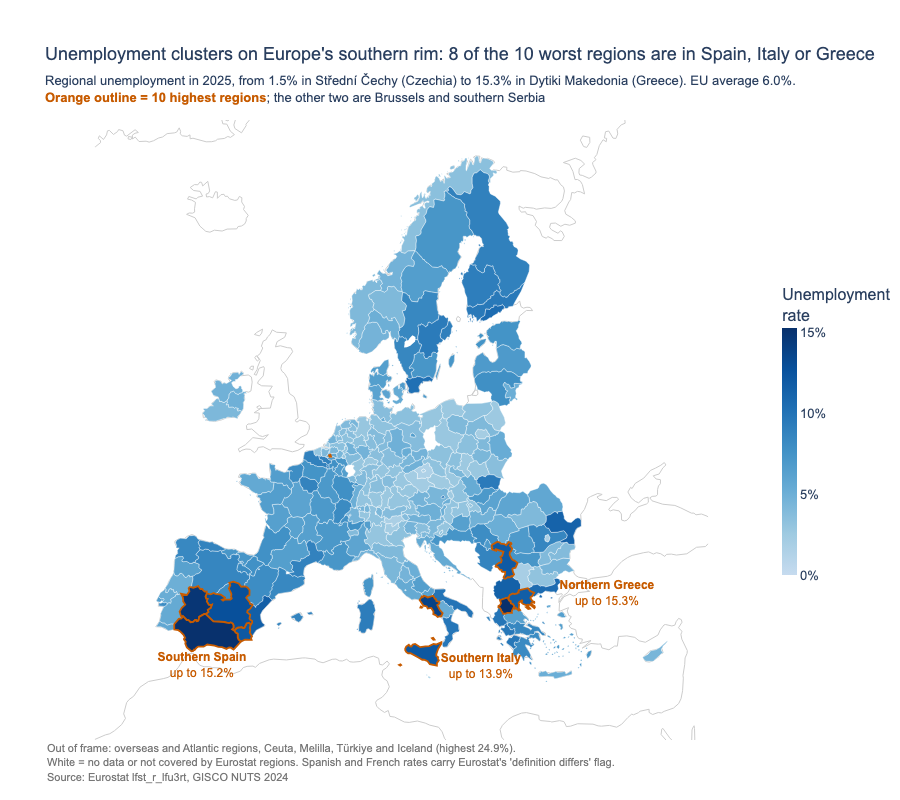

In [3]:
# Task 2 — unemployment across European regions (NUTS 2), 2025

# Load the GeoJSON
with open('../data/nuts2_2024_20m.geojson', 'r') as file:
    my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
print(my_geojson['features'][0]['properties'])

# Region names come from the GeoJSON, rates from Eurostat; NUTS_ID links the two
regions = pd.DataFrame([f['properties'] for f in my_geojson['features']])
unemployment = pd.read_csv('../data/eu_unemployment_nuts2.csv')
rates_2025 = unemployment.loc[unemployment['TIME_PERIOD'] == 2025].dropna(subset=['OBS_VALUE'])
eu_avg = rates_2025.loc[rates_2025['geo'] == 'EU27_2020', 'OBS_VALUE'].iloc[0]

df = regions[['NUTS_ID', 'NAME_LATN', 'CNTR_CODE', 'NAME_ENGL']].merge(
    rates_2025[['geo', 'OBS_VALUE']], left_on='NUTS_ID', right_on='geo'
).rename(columns={'NAME_LATN': 'region', 'NAME_ENGL': 'country', 'OBS_VALUE': 'rate'})
print(f"Matched {len(df)} of {len(regions)} GeoJSON regions; no data for "
      f"{sorted(set(regions['NUTS_ID']) - set(df['NUTS_ID']))}")

# Regions far from the European mainland would shrink the map, so they stay out of frame.
off_map_ids = ['FRY1', 'FRY2', 'FRY3', 'FRY4', 'FRY5', 'ES63', 'ES64', 'ES70', 'PT20', 'PT30']
is_off_map = df['NUTS_ID'].isin(off_map_ids) | df['CNTR_CODE'].isin(['TR', 'IS'])
off_map_peak = df.loc[is_off_map, 'rate'].max()

# Sorted so the highlighted regions are drawn last and their outlines stay on top
df_map = df[~is_off_map].sort_values('rate')
top10 = df_map.nlargest(10, 'rate')
n_south = top10['CNTR_CODE'].isin(['ES', 'IT', 'EL']).sum()
peak_by_country = top10.groupby('CNTR_CODE')['rate'].max()
highest, lowest_region = df_map.iloc[-1], df_map.iloc[0]
print(top10[['region', 'country', 'rate']].to_string(index=False))
print(f"Lowest: {lowest_region['region']} ({lowest_region['country']}) {lowest_region['rate']}%")
print(f"Highest rate out of frame: {off_map_peak}%")

HIGHLIGHT = '#C75B00'
is_top = df_map['NUTS_ID'].isin(top10['NUTS_ID'])

fig = px.choropleth(
    data_frame=df_map,
    geojson=my_geojson,
    locations='NUTS_ID',
    featureidkey='properties.NUTS_ID',
    color='rate',
    color_continuous_scale=px.colors.sequential.Blues[2:],
    range_color=[0, df_map['rate'].max()],
    fitbounds='locations',
    hover_name='region',
    hover_data={'country': True, 'rate': ':.1f', 'NUTS_ID': False},
    labels={'rate': 'Unemployment rate (%)', 'country': 'Country'},
    template='plotly_white',
    height=800, width=900
)

fig.update_traces(
    marker_line_color=is_top.map({True: HIGHLIGHT, False: 'white'}).tolist(),
    marker_line_width=is_top.map({True: 1.8, False: 0.4}).tolist()
)

# Label each southern cluster in the sea next to it
fig.add_scattergeo(
    lon=[-4.5, 18.8, 30.5], lat=[35.2, 36.4, 39.9],
    text=[
        f"<b>Southern Spain</b><br>up to {peak_by_country['ES']:.1f}%",
        f"<b>Southern Italy</b><br>up to {peak_by_country['IT']:.1f}%",
        f"<b>Northern Greece</b><br>up to {peak_by_country['EL']:.1f}%"
    ],
    mode='text',
    textfont=dict(color=HIGHLIGHT, size=12),
    hoverinfo='skip',
    showlegend=False
)

fig.add_annotation(
    xref='paper', yref='paper', x=0, y=0, xanchor='left', yanchor='top', align='left',
    text=(
        "Out of frame: overseas and Atlantic regions, Ceuta, Melilla, Türkiye and Iceland "
        f"(highest {off_map_peak:.1f}%).<br>"
        "White = no data or not covered by Eurostat regions. Spanish and French rates carry Eurostat's 'definition differs' flag.<br>"
        "Source: Eurostat lfst_r_lfu3rt, GISCO NUTS 2024"
    ),
    showarrow=False, font=dict(size=11, color='#777777')
)

fig.update_layout(
    title=dict(
        text=f"Unemployment clusters on Europe's southern rim: "
             f"{n_south} of the 10 worst regions are in Spain, Italy or Greece",
        subtitle=dict(text=(
            f"Regional unemployment in 2025, from {lowest_region['rate']:.1f}% in {lowest_region['region']} ({lowest_region['country']}) "
            f"to {highest['rate']:.1f}% in {highest['region']} ({highest['country']}). EU average {eu_avg:.1f}%.<br>"
            f"<span style='color:{HIGHLIGHT}'><b>Orange outline = 10 highest regions</b></span>; the other two are Brussels and southern Serbia"
        ))
    ),
    font=dict(family='Arial', size=13),
    geo=dict(
        projection_type='azimuthal equal area',
        showframe=False,
        showcoastlines=True,
        coastlinecolor='#CCCCCC',
        showcountries=False,
        showland=True,
        landcolor='white'
    ),
    coloraxis_colorbar=dict(title='Unemployment<br>rate', ticksuffix='%', thickness=15, len=0.5),
    margin=dict(l=45, r=0, t=120, b=60)
)

fig.show()